# Fine-tuning a Multimodal Model for Hallucination Detection
## Stage 1 — Real Data Only Baseline

**Thesis context**: This notebook establishes the *real-data-only* baseline before synthetic augmentation.  
The final comparison will be: `Real data` vs `Real + Synthetic` on the official test set metrics.

---

### Architecture

```
Input: [Image] + [Original Question] + [VLM Response to Analyse]
          ↓
   Qwen2-VL (Visual Encoder + Language Model)
          ↓  QLoRA fine-tuning (4-bit base + LoRA adapters)
   Output: JSON → [{"text": "...", "prob": 0.8, "label": "invention"}, ...]
          ↓
   Post-processing: map text spans → character (start, end) positions
          ↓
   Evaluation: Span IoU | Spearman ρ | Category F1
```

### Why Qwen2-VL?
| Property | Benefit for this task |
|---|---|
| Native ZH/FR/IT/EN support | Responses in all 4 languages are understood equally |
| Strong visual grounding | Detects what is / isn't in the image accurately |
| 2B & 7B variants | 2B fits free Colab T4; 7B fits Colab Pro A100/L4 |
| Unsloth integration | 2× faster training, 60% less VRAM via QLoRA |

### Training objective
Supervised fine-tuning (SFT) with **JSON generation**:  
- Target: `[{"text": "<exact span>", "prob": <float>, "label": "<category>"}]`  
- Clean responses target: `[]`  
- Loss computed only on the **assistant tokens** (not the prompt)


## Setup

**Before running:**
1. **Runtime → Change runtime type → GPU** (T4 for free tier, A100/L4 for Pro)
2. Upload your project to Google Drive:
   ```
   MyDrive/shroom-visions/
   ├── distrib/          ← all 8 JSONL files
   └── shroom-vis-images/  ← all image files
   ```
3. Set `MODEL_ID` in the Configuration cell below:
   - **Free T4**: `"unsloth/Qwen2-VL-2B-Instruct"`  (~5 GB VRAM)
   - **Pro A100/L4**: `"unsloth/Qwen2-VL-7B-Instruct"`  (~12 GB VRAM)


In [ ]:
# ── Installation (run once per session) ───────────────────────────────────────
import subprocess, sys

# Unsloth — optimised QLoRA for vision models (2× faster, 60% less VRAM)
subprocess.run([sys.executable, "-m", "pip", "install",
    "unsloth[colab-new] @ git+https://github.com/unslothai/unsloth.git",
    "--quiet"], check=False)

subprocess.run([sys.executable, "-m", "pip", "install",
    "--no-deps", "trl", "peft", "accelerate", "bitsandbytes",
    "--quiet"], check=False)

# Qwen2-VL image processing utilities
subprocess.run([sys.executable, "-m", "pip", "install",
    "qwen-vl-utils", "transformers>=4.45.0",
    "scipy", "scikit-learn", "matplotlib", "seaborn",
    "--quiet"], check=False)

print("Installation complete — restart runtime if this is the first run.")

Installation complete — restart runtime if this is the first run.


In [ ]:
import json, re, os, io, difflib, random, warnings, math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from collections import Counter, defaultdict
from typing import Optional
from scipy.stats import spearmanr
from tqdm.auto import tqdm

import torch
from torch.utils.data import Dataset as TorchDataset
from datasets import Dataset
from PIL import Image
from qwen_vl_utils import process_vision_info

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', font_scale=1.1)

print(f"PyTorch  : {torch.__version__}")
print(f"CUDA     : {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"GPU      : {torch.cuda.get_device_name(0)}")
    print(f"VRAM     : {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")

PyTorch  : 2.10.0+cu128
CUDA     : True
GPU      : NVIDIA A100-SXM4-40GB
VRAM     : 42.4 GB


In [ ]:
# ═══════════════════════════════════════════════════════════════════════════════
# CONFIGURATION — edit here
# ═══════════════════════════════════════════════════════════════════════════════

# ── Model ─────────────────────────────────────────────────────────────────────
# Free T4 (16 GB)      → "unsloth/Qwen2-VL-2B-Instruct"   (recommended)
# Pro A100/L4 (≥24 GB) → "unsloth/Qwen2-VL-7B-Instruct"   (better quality)
MODEL_ID = "unsloth/Qwen2-VL-7B-Instruct"

# ── LoRA hyperparameters ──────────────────────────────────────────────────────
LORA_R          = 16       # rank; try 8 for less memory, 32 for more capacity
LORA_ALPHA      = 16       # typically equal to LORA_R
LORA_DROPOUT    = 0.0      # 0 works best with unsloth

# ── Training ──────────────────────────────────────────────────────────────────
NUM_EPOCHS      = 2        # 2 epochs is sufficient for SFT with this dataset size
LR              = 2e-4     # learning rate (AdamW with cosine schedule)
BATCH_SIZE      = 1        # per-device; keep 1 for T4
GRAD_ACCUM      = 8        # effective batch = BATCH_SIZE * GRAD_ACCUM = 8
WARMUP_STEPS    = 50
MAX_SEQ_LEN     = 2048     # covers p99 of all responses + labels + instruction
MAX_NEW_TOKENS  = 512      # max JSON output tokens during inference
SAVE_STEPS      = 200      # checkpoint every N optimizer steps
LOG_STEPS       = 10

# ── Languages to train on ─────────────────────────────────────────────────────
TRAIN_LANGS     = ["en", "fr", "it", "zh"]  # all 4 for multilingual baseline
VAL_FRACTION    = 0.10     # 10% of each language → held-out validation set
RANDOM_SEED     = 42

# ── Paths ─────────────────────────────────────────────────────────────────────
from google.colab import drive; drive.mount('/content/drive')
DRIVE_BASE = Path('/content/drive/MyDrive/shroom-visions')
# DRIVE_BASE  = Path('.')                      # adjust when running on Colab
DATA_DIR    = DRIVE_BASE / 'distrib'
IMAGE_DIR   = DRIVE_BASE / 'shroom-vis-images'
OUTPUT_DIR  = DRIVE_BASE / 'ft_predictions'
CKPT_DIR    = DRIVE_BASE / 'ft_checkpoints'

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
CKPT_DIR.mkdir(parents=True, exist_ok=True)

# ── Task constants ─────────────────────────────────────────────────────────────
# Note: the actual label string in the JSONL is 'OCR' (not 'ocr_problem')
LABEL_ORDER   = ['invention', 'mischaracterization', 'OCR', 'miscounting', 'other']
VALID_LABELS  = set(LABEL_ORDER)

LANGUAGES  = ['en', 'fr', 'it', 'zh']
LANG_NAMES = {'en': 'English', 'fr': 'French', 'it': 'Italian', 'zh': 'Chinese'}

random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)

print(f"Model    : {MODEL_ID}")
print(f"Data dir : {DATA_DIR.resolve()}")
print(f"Image dir: {IMAGE_DIR.resolve()}")
print(f"Output   : {OUTPUT_DIR.resolve()}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Model    : unsloth/Qwen2-VL-7B-Instruct
Data dir : /content/drive/MyDrive/shroom-visions/distrib
Image dir: /content/drive/MyDrive/shroom-visions/shroom-vis-images
Output   : /content/drive/MyDrive/shroom-visions/ft_predictions


---
## 1 — Data Preparation

**Training format**: Each sample becomes an instruction-following conversation:

```
User:  [IMAGE] + "Question: ...\nVLM Response: ..."
Assistant:  '[{"text": "hidden", "prob": 0.333, "label": "mischaracterization"}]'
```

- Span text is extracted verbatim from `response[start:end]` — the model learns to copy exact text
- Clean samples (no hallucination) → assistant outputs `[]`
- **Loss is computed only on assistant tokens** (instruction tokens are masked with -100)


In [ ]:
def load_jsonl(path: Path) -> list:
    return [json.loads(l) for l in path.read_text(encoding='utf-8').splitlines() if l.strip()]

train_raw, test_raw = {}, {}
for lang in LANGUAGES:
    train_raw[lang] = load_jsonl(DATA_DIR / f'shroom-vision.train.{lang}.labeled.jsonl')
    test_raw[lang]  = load_jsonl(DATA_DIR / f'shroom-vision.test.{lang}.unlabeled.jsonl')
    print(f'{lang.upper()}: {len(train_raw[lang])} train  |  {len(test_raw[lang])} test')

total_train = sum(len(v) for v in train_raw.values())
print(f'\nTotal train samples (all langs): {total_train:,}')

EN: 3799 train  |  1201 test
FR: 3767 train  |  1233 test
IT: 3746 train  |  1254 test
ZH: 3790 train  |  1210 test

Total train samples (all langs): 15,102


In [ ]:
def resolve_image_path(image_name: str, image_dir: Path) -> Optional[Path]:
    """Find the image file, trying alternate extensions if needed."""
    p = image_dir / image_name
    if p.exists():
        return p
    for ext in ['.jpg', '.jpeg', '.png', '.JPG', '.JPEG', '.PNG']:
        alt = p.with_suffix(ext)
        if alt.exists():
            return alt
    return None


INSTRUCTION = """Identify all hallucinated text spans in the vision model's response.
A hallucination is text that is factually incorrect compared to what is actually visible in the image.

Categories:
- invention: entities or facts completely absent from the image
- mischaracterization: visible content described incorrectly (wrong color, shape, count, etc.)
- OCR: text visible in the image is misread or mistranscribed
- miscounting: wrong quantity of visible items
- other: hallucination not fitting the above

Return ONLY a JSON array:
[{"text": "<exact text copied from the response>", "prob": <0.0-1.0>, "label": "<category>"}]
If there are no hallucinations, return: []"""


def build_conversation(sample: dict, image_dir: Path) -> Optional[dict]:
    """
    Convert one training sample into an instruction-following conversation dict.
    Returns None if the image file is not found (sample is skipped).

    IMPORTANT: both user and assistant 'content' fields must be lists of dicts
    (never a plain string) so that PyArrow can build a uniform schema when
    calling Dataset.from_list().  The format mirrors Qwen2-VL's chat template.
    """
    img_path = resolve_image_path(sample['image_name'], image_dir)
    if img_path is None:
        return None

    response = sample['response']
    labels   = sample.get('labels', [])

    # Build JSON target: extract span text verbatim from the response
    target_spans = []
    for lb in sorted(labels, key=lambda x: x['start']):
        span_text = response[lb['start']:lb['end']]
        if span_text.strip():           # skip zero-width or whitespace-only spans
            target_spans.append({
                'text':  span_text,
                'prob':  round(float(lb['prob']), 4),
                'label': lb['label'],
            })
    target_json = json.dumps(target_spans, ensure_ascii=False)

    user_text = (
        f"{INSTRUCTION}\n\n"
        f"Question asked: {sample['prompt']}\n\n"
        f"VLM response to analyse:\n{response}"
    )

    return {
        'messages': [
            {
                'role': 'user',
                'content': [
                    {'type': 'image', 'image': str(img_path)},
                    {'type': 'text',  'text':  user_text},
                ],
            },
            {
                # content must also be a list so every row has the same schema
                'role':    'assistant',
                'content': [{'type': 'text', 'text': target_json}],
            },
        ],
        # Keep metadata for evaluation (stripped out before passing to collator)
        '_id':       sample['id'],
        '_lang':     sample.get('language', ''),
        '_response': response,
        '_labels':   labels,
    }


def build_inference_conversation(sample: dict, image_dir: Path) -> Optional[dict]:
    """Same structure but WITHOUT the assistant turn (for generation)."""
    img_path = resolve_image_path(sample['image_name'], image_dir)
    if img_path is None:
        return None
    user_text = (
        f"{INSTRUCTION}\n\n"
        f"Question asked: {sample['prompt']}\n\n"
        f"VLM response to analyse:\n{sample['response']}"
    )
    return {
        'messages': [{
            'role': 'user',
            'content': [
                {'type': 'image', 'image': str(img_path)},
                {'type': 'text',  'text':  user_text},
            ],
        }],
        '_id':       sample['id'],
        '_lang':     sample.get('language', ''),
        '_response': sample['response'],
        '_labels':   sample.get('labels', []),
    }


print('Conversation builder ready.')


Conversation builder ready.


In [ ]:
from sklearn.model_selection import train_test_split

all_train_convs, all_val_convs = [], []
skipped_total = 0

for lang in TRAIN_LANGS:
    samples = train_raw[lang]

    # Stratified split: maintain hallucinated / clean ratio
    hallu  = [s for s in samples if s.get('labels')]
    clean  = [s for s in samples if not s.get('labels')]

    h_tr, h_val = train_test_split(hallu, test_size=VAL_FRACTION, random_state=RANDOM_SEED)
    c_tr, c_val = train_test_split(clean, test_size=VAL_FRACTION, random_state=RANDOM_SEED)

    lang_train = h_tr + c_tr
    lang_val   = h_val + c_val

    # Convert to conversation format (skip missing images)
    skipped = 0
    for s in lang_train:
        conv = build_conversation(s, IMAGE_DIR)
        if conv:
            all_train_convs.append(conv)
        else:
            skipped += 1

    for s in lang_val:
        conv = build_inference_conversation(s, IMAGE_DIR)
        if conv:
            all_val_convs.append(conv)
        else:
            skipped += 1

    skipped_total += skipped
    print(f'{lang.upper()}: {len(h_tr)+len(c_tr)} train  |  {len(h_val)+len(c_val)} val  |  {skipped} skipped (missing images)')

random.shuffle(all_train_convs)

print(f'\nTotal train conversations : {len(all_train_convs):,}')
print(f'Total val   conversations : {len(all_val_convs):,}')
print(f'Skipped (missing images)  : {skipped_total}')

EN: 3418 train  |  381 val  |  0 skipped (missing images)
FR: 3389 train  |  378 val  |  0 skipped (missing images)
IT: 3371 train  |  375 val  |  0 skipped (missing images)
ZH: 3410 train  |  380 val  |  0 skipped (missing images)

Total train conversations : 13,588
Total val   conversations : 1,514
Skipped (missing images)  : 0


=== TRAINING EXAMPLE ===
ID   : train-fr-14009
Lang : fr

USER prompt (truncated):
Identify all hallucinated text spans in the vision model's response.
A hallucination is text that is factually incorrect compared to what is actually visible in the image.

Categories:
- invention: entities or facts completely absent from the image
- mischaracterization: visible content described incorrectly (wrong color, shape, count, etc.)
- OCR: text visible in the image is misread or mistransc ...

ASSISTANT target (ground truth):
[{"text": "The bicycle in the image appears to be leaning against a wall or a similar surface. It's difficult to determine whether the bicycle is currently lent out or not just from the image. If someone were using the bicycle, it would typically be ridden rather than leaned against a wall like it is here. However, without more context, such as a person nearby or a sign indicating that the bicycle has been lent, it's not possible to definitively say whether it's lent out or

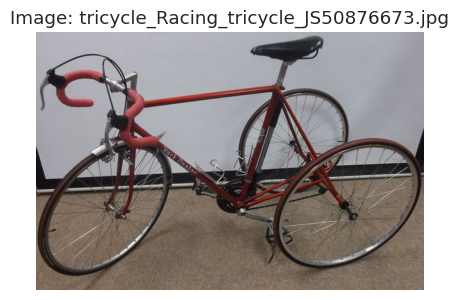

In [ ]:
# ── Show one training example ─────────────────────────────────────────────────
ex = next(c for c in all_train_convs if c['_labels'])   # pick one with hallucinations

print('=== TRAINING EXAMPLE ===')
print(f'ID   : {ex["_id"]}')
print(f'Lang : {ex["_lang"]}')
print()
print('USER prompt (truncated):')
print(ex['messages'][0]['content'][1]['text'][:400], '...')
print()
print('ASSISTANT target (ground truth):')
print(ex['messages'][1]['content'][0]['text'])
print()
print('Gold labels:')
print(ex['_labels'][:3])

# Show the image
img_path = ex['messages'][0]['content'][0]['image']
img = Image.open(img_path)
plt.figure(figsize=(5, 4))
plt.imshow(img)
plt.axis('off')
plt.title(f"Image: {Path(img_path).name}")
plt.show()

In [ ]:
# Training set statistics
n_hallu = sum(1 for c in all_train_convs if c['_labels'])
n_clean = len(all_train_convs) - n_hallu
label_dist = Counter(lb['label'] for c in all_train_convs for lb in c['_labels'])

print('Training set composition:')
print(f'  Hallucinated samples : {n_hallu:,} ({n_hallu/len(all_train_convs)*100:.1f}%)')
print(f'  Clean samples        : {n_clean:,} ({n_clean/len(all_train_convs)*100:.1f}%)')
print(f'  Total spans          : {sum(label_dist.values()):,}')
print('\n  Label distribution:')
for cat in LABEL_ORDER:
    n = label_dist.get(cat, 0)
    total = sum(label_dist.values())
    bar = '█' * int(n/total*30)
    print(f'    {cat:22s}: {n:6,}  ({n/total*100:5.1f}%)  {bar}')

Training set composition:
  Hallucinated samples : 9,725 (71.6%)
  Clean samples        : 3,863 (28.4%)
  Total spans          : 37,877

  Label distribution:
    invention             : 16,431  ( 43.4%)  █████████████
    mischaracterization   : 15,309  ( 40.4%)  ████████████
    OCR                   :  1,426  (  3.8%)  █
    miscounting           :  3,095  (  8.2%)  ██
    other                 :  1,616  (  4.3%)  █


---
## 2 — Model Loading & LoRA Configuration

**QLoRA setup**:
- Base model loaded in **4-bit NF4** quantization (bitsandbytes) → ~4× memory reduction
- **LoRA adapters** injected into attention and MLP layers — only these are trained
- **Gradient checkpointing** (`unsloth` mode) trades compute for memory
- Only language layers fine-tuned by default (`finetune_vision_layers=False`);
  set to `True` for better performance if VRAM allows


In [ ]:
from unsloth import FastVisionModel, is_bf16_supported

print(f'Loading {MODEL_ID} in 4-bit...')
model, processor = FastVisionModel.from_pretrained(
    MODEL_ID,
    load_in_4bit=True,
    use_gradient_checkpointing='unsloth',   # activates rematerialisation
)

print(f'Base model loaded.')
print(f'Model dtype : {model.dtype}')

# VRAM after loading
if torch.cuda.is_available():
    used_gb = torch.cuda.memory_allocated() / 1e9
    total_gb = torch.cuda.get_device_properties(0).total_memory / 1e9
    print(f'VRAM used   : {used_gb:.1f} GB / {total_gb:.1f} GB')

🦥 Unsloth: Will patch your computer to enable 2x faster free finetuning.
Unsloth: Your Flash Attention 2 installation seems to be broken. Using Xformers instead. No performance changes will be seen.
🦥 Unsloth Zoo will now patch everything to make training faster!
Loading unsloth/Qwen2-VL-7B-Instruct in 4-bit...
==((====))==  Unsloth 2026.5.2: Fast Qwen2_Vl patching. Transformers: 5.5.0.
   \\   /|    NVIDIA A100-SXM4-40GB. Num GPUs = 1. Max memory: 39.494 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.10.0+cu128. CUDA: 8.0. CUDA Toolkit: 12.8. Triton: 3.6.0
\        /    Bfloat16 = TRUE. FA [Xformers = None. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!


model.safetensors:   0%|          | 0.00/6.85G [00:00<?, ?B/s]

Loading weights:   0%|          | 0/730 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/238 [00:00<?, ?B/s]

preprocessor_config.json:   0%|          | 0.00/572 [00:00<?, ?B/s]

chat_template.json: 0.00B [00:00, ?B/s]

... (3 outputs left out)

tokenizer.json:   0%|          | 0.00/11.4M [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/392 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/614 [00:00<?, ?B/s]

Base model loaded.
Model dtype : torch.bfloat16
VRAM used   : 6.9 GB / 42.4 GB


In [ ]:
model = FastVisionModel.get_peft_model(
    model,
    # Set finetune_vision_layers=True for higher quality (needs more VRAM)
    finetune_vision_layers     = False,   # freeze visual encoder, train language only
    finetune_language_layers   = True,
    finetune_attention_modules = True,
    finetune_mlp_modules       = True,
    r            = LORA_R,
    lora_alpha   = LORA_ALPHA,
    lora_dropout = LORA_DROPOUT,
    bias         = 'none',
    random_state = RANDOM_SEED,
    use_rslora   = False,
    loftq_config = None,
)

# Count trainable vs frozen parameters
total_params     = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'Total parameters      : {total_params/1e6:.1f} M')
print(f'Trainable (LoRA)      : {trainable_params/1e6:.2f} M  ({trainable_params/total_params*100:.2f}%)')
print(f'Frozen (base model)   : {(total_params-trainable_params)/1e6:.1f} M')

if torch.cuda.is_available():
    used_gb = torch.cuda.memory_allocated() / 1e9
    total_gb = torch.cuda.get_device_properties(0).total_memory / 1e9
    print(f'VRAM after LoRA       : {used_gb:.1f} GB / {total_gb:.1f} GB')

Total parameters      : 5052.7 M
Trainable (LoRA)      : 40.37 M  (0.80%)
Frozen (base model)   : 5012.3 M
VRAM after LoRA       : 7.0 GB / 42.4 GB


---
## 3 — Training

**Effective batch size** = `BATCH_SIZE × GRAD_ACCUM` = 1 × 8 = **8**  
**Estimated steps/epoch** ≈ `len(train_set) / effective_batch`  
**Estimated time** (T4): ~1.5–2 hours for 2 epochs on 13,000 samples  
**Estimated time** (A100): ~20–30 minutes  

Training uses the **unsloth `UnslothVisionDataCollator`**, which:
- Loads images from disk and applies Qwen2-VL's visual preprocessing
- Builds `input_ids`, `attention_mask`, and `pixel_values` tensors
- Masks all user-turn tokens with `-100` so loss is computed on assistant output only


In [ ]:
from trl import SFTTrainer, SFTConfig
from unsloth.trainer import UnslothVisionDataCollator

# Build HuggingFace Dataset (keep only the 'messages' field for the collator)
hf_train = Dataset.from_list([{'messages': c['messages']} for c in all_train_convs])

print(f'Training dataset: {len(hf_train):,} samples')
steps_per_epoch = math.ceil(len(hf_train) / (BATCH_SIZE * GRAD_ACCUM))
total_steps     = steps_per_epoch * NUM_EPOCHS
print(f'Steps per epoch : {steps_per_epoch}')
print(f'Total steps     : {total_steps}  ({NUM_EPOCHS} epochs)')

trainer = SFTTrainer(
    model           = model,
    tokenizer       = processor.tokenizer,
    data_collator   = UnslothVisionDataCollator(model, processor),
    train_dataset   = hf_train,
    args = SFTConfig(
        output_dir                   = str(CKPT_DIR),
        num_train_epochs             = NUM_EPOCHS,
        per_device_train_batch_size  = BATCH_SIZE,
        gradient_accumulation_steps  = GRAD_ACCUM,
        warmup_steps                 = WARMUP_STEPS,
        learning_rate                = LR,
        lr_scheduler_type            = 'cosine',
        fp16                         = not is_bf16_supported(),
        bf16                         = is_bf16_supported(),
        logging_steps                = LOG_STEPS,
        save_steps                   = SAVE_STEPS,
        save_total_limit             = 2,           # keep only last 2 checkpoints
        optim                        = 'adamw_8bit',
        weight_decay                 = 0.01,
        seed                         = RANDOM_SEED,
        report_to                    = 'none',      # set 'wandb' for W&B logging
        remove_unused_columns        = False,
        dataset_text_field           = '',
        dataset_kwargs               = {'skip_prepare_dataset': True},
        max_seq_length               = MAX_SEQ_LEN,
    ),
)

print('Trainer configured.')

Training dataset: 13,588 samples
Steps per epoch : 1699
Total steps     : 3398  (2 epochs)
Unsloth: Model does not have a default image size - using 512
Trainer configured.


In [ ]:
# ── Train ─────────────────────────────────────────────────────────────────────
print('Starting training...')
print('Monitor loss in the output below.\n')

train_result = trainer.train()

print('\nTraining complete!')
print(f'  Total steps     : {train_result.global_step}')
print(f'  Training loss   : {train_result.training_loss:.4f}')
print(f'  Runtime         : {train_result.metrics.get("train_runtime", 0)/60:.1f} min')

# Save final LoRA adapter weights
adapter_dir = CKPT_DIR / 'final_adapter'
model.save_pretrained(adapter_dir)
processor.save_pretrained(adapter_dir)
print(f'\nLoRA adapter saved → {adapter_dir}')

The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'eos_token_id': 151645, 'bos_token_id': None}.


Starting training...
Monitor loss in the output below.



==((====))==  Unsloth - 2x faster free finetuning | Num GPUs used = 1
   \\   /|    Num examples = 13,588 | Num Epochs = 2 | Total steps = 3,398
O^O/ \_/ \    Batch size per device = 1 | Gradient accumulation steps = 8
\        /    Data Parallel GPUs = 1 | Total batch size (1 x 8 x 1) = 8
 "-____-"     Trainable parameters = 40,370,176 of 8,331,745,792 (0.48% trained)


Unsloth: Will smartly offload gradients to save VRAM!
Unsloth: Double buffering enabled (parallel H2D + compute) for backward pass.


Step,Training Loss
10,2.101980
20,1.519531
30,0.728793
40,0.524012
50,0.498290
60,0.486055
70,0.448452
80,0.382560
90,0.475684
100,0.478248


Unsloth: Restored added_tokens_decoder metadata in /content/drive/MyDrive/shroom-visions/ft_checkpoints/checkpoint-200/tokenizer_config.json.
Unsloth: Restored added_tokens_decoder metadata in /content/drive/MyDrive/shroom-visions/ft_checkpoints/checkpoint-400/tokenizer_config.json.
Unsloth: Restored added_tokens_decoder metadata in /content/drive/MyDrive/shroom-visions/ft_checkpoints/checkpoint-600/tokenizer_config.json.
Unsloth: Restored added_tokens_decoder metadata in /content/drive/MyDrive/shroom-visions/ft_checkpoints/checkpoint-800/tokenizer_config.json.
Unsloth: Restored added_tokens_decoder metadata in /content/drive/MyDrive/shroom-visions/ft_checkpoints/checkpoint-1000/tokenizer_config.json.
Unsloth: Restored added_tokens_decoder metadata in /content/drive/MyDrive/shroom-visions/ft_checkpoints/checkpoint-1200/tokenizer_config.json.
Unsloth: Restored added_tokens_decoder metadata in /content/drive/MyDrive/shroom-visions/ft_checkpoints/checkpoint-1400/tokenizer_config.json.
Uns


Training complete!
  Total steps     : 3398
  Training loss   : 0.3377
  Runtime         : 411.9 min


Unsloth: Restored added_tokens_decoder metadata in /content/drive/MyDrive/shroom-visions/ft_checkpoints/final_adapter/tokenizer_config.json.



LoRA adapter saved → /content/drive/MyDrive/shroom-visions/ft_checkpoints/final_adapter


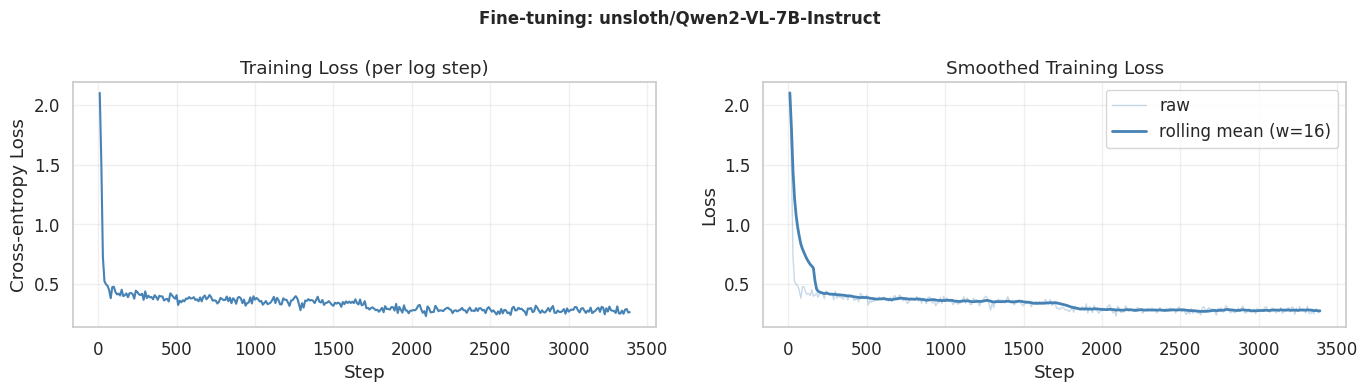

Initial loss: 2.1020   Final loss: 0.2657


In [ ]:
# ── Plot training loss curve ──────────────────────────────────────────────────
log_history = trainer.state.log_history
train_logs  = [e for e in log_history if 'loss' in e and 'eval_loss' not in e]

if train_logs:
    steps  = [e['step'] for e in train_logs]
    losses = [e['loss'] for e in train_logs]

    fig, axes = plt.subplots(1, 2, figsize=(14, 4))

    axes[0].plot(steps, losses, color='steelblue', linewidth=1.5)
    axes[0].set_title('Training Loss (per log step)')
    axes[0].set_xlabel('Step'); axes[0].set_ylabel('Cross-entropy Loss')
    axes[0].grid(True, alpha=0.3)

    # Smoothed loss (rolling mean)
    window = max(1, len(losses) // 20)
    smoothed = pd.Series(losses).rolling(window, min_periods=1).mean()
    axes[1].plot(steps, losses,   alpha=0.3, color='steelblue', linewidth=1,   label='raw')
    axes[1].plot(steps, smoothed, color='steelblue', linewidth=2, label=f'rolling mean (w={window})')
    axes[1].set_title('Smoothed Training Loss')
    axes[1].set_xlabel('Step'); axes[1].set_ylabel('Loss')
    axes[1].legend(); axes[1].grid(True, alpha=0.3)

    plt.suptitle(f'Fine-tuning: {MODEL_ID}', fontsize=12, fontweight='bold')
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / 'training_loss.png', dpi=150, bbox_inches='tight')
    plt.show()
    print(f'Initial loss: {losses[0]:.4f}   Final loss: {losses[-1]:.4f}')
else:
    print('No log history found — training may not have run.')

---
## 4 — Inference & Span Extraction

The fine-tuned model outputs a JSON string. We then:
1. Parse the JSON → list of `{text, prob, label}`
2. Find each quoted `text` in the original response via exact → fuzzy matching
3. Convert to `{start, end, prob, label}` format for evaluation


In [ ]:
# Switch model to fast inference mode (disables gradient checkpointing, etc.)
FastVisionModel.for_inference(model)

device = next(model.parameters()).device
print(f'Inference device: {device}')


def run_inference(conv: dict) -> str:
    """
    Run the fine-tuned model on a single conversation (without assistant turn).
    Returns the raw generated string (expected to be a JSON array).
    """
    msgs = conv['messages']  # user turn only
    text_input = processor.apply_chat_template(
        msgs, tokenize=False, add_generation_prompt=True
    )
    image_inputs, video_inputs = process_vision_info(msgs)

    inputs = processor(
        text=[text_input],
        images=image_inputs,
        videos=video_inputs,
        padding=True,
        return_tensors='pt',
    ).to(device)

    with torch.no_grad():
        output_ids = model.generate(
            **inputs,
            max_new_tokens = MAX_NEW_TOKENS,
            do_sample      = False,         # greedy decoding → deterministic
            temperature    = 1.0,
            pad_token_id   = processor.tokenizer.pad_token_id,
        )

    # Strip the prompt tokens, decode only new tokens
    generated = output_ids[:, inputs['input_ids'].shape[1]:]
    return processor.batch_decode(generated, skip_special_tokens=True)[0].strip()


print('Inference function ready.')

Inference device: cuda:0
Inference function ready.


In [ ]:
# ── JSON parsing ──────────────────────────────────────────────────────────────

LABEL_NORMALISE = {
    'mischaracterisation': 'mischaracterization',
    'mis-characterization': 'mischaracterization',
    'ocr_problem': 'OCR',
    'ocr problem': 'OCR',
    'ocr':         'OCR',
    'fabrication': 'invention',
    'count':       'miscounting',
}

def parse_model_output(raw: str) -> list:
    """Parse JSON string → list of {text, prob, label}."""
    m = re.search(r'\[.*\]', raw, re.DOTALL)
    if not m:
        return []
    try:
        spans = json.loads(m.group())
    except json.JSONDecodeError:
        return []

    out = []
    for sp in spans:
        if not isinstance(sp, dict) or 'text' not in sp:
            continue
        text  = str(sp['text']).strip()
        if not text:
            continue
        label = str(sp.get('label', 'other')).lower().strip()
        label = LABEL_NORMALISE.get(label, label)
        if label not in VALID_LABELS:
            label = 'other'
        prob = max(0.0, min(1.0, float(sp.get('prob', 0.8))))
        out.append({'text': text, 'prob': prob, 'label': label})
    return out


# ── Span position mapping ─────────────────────────────────────────────────────

def find_span_pos(response: str, text: str) -> Optional[tuple]:
    """Map text snippet → (start, end) in response. Returns None if not found."""
    if not text:
        return None
    # 1. Exact
    pos = response.find(text)
    if pos != -1:
        return pos, pos + len(text)
    # 2. Case-insensitive
    pos = response.lower().find(text.lower())
    if pos != -1:
        return pos, pos + len(text)
    # 3. Strip markdown then exact
    stripped = re.sub(r'[\*\_`]+', '', text).strip()
    if stripped and stripped != text:
        pos = response.lower().find(stripped.lower())
        if pos != -1:
            return pos, pos + len(stripped)
    # 4. Fuzzy sliding window (for spans >= 8 chars)
    if len(text) >= 8:
        tl, rl = text.lower(), response.lower()
        tlen = len(text)
        step = max(1, tlen // 4)
        best_r, best_pos = 0.0, 0
        for i in range(0, max(1, len(response) - tlen + 1), step):
            r = difflib.SequenceMatcher(None, rl[i:i+tlen], tl).ratio()
            if r > best_r:
                best_r, best_pos = r, i
        # Refine locally
        for i in range(max(0, best_pos - step), min(len(response)-tlen+1, best_pos+step+1)):
            r = difflib.SequenceMatcher(None, rl[i:i+tlen], tl).ratio()
            if r > best_r:
                best_r, best_pos = r, i
        if best_r >= 0.80:
            return best_pos, best_pos + tlen
    return None


def map_spans_to_positions(response: str, parsed: list) -> list:
    """Convert [{text,prob,label}] → [{start,end,prob,label}]."""
    result, used = [], set()
    for sp in parsed:
        pos = find_span_pos(response, sp['text'])
        if pos is None:
            continue
        start, end = pos
        overlap = len(set(range(start, end)) & used)
        if overlap > (end - start) * 0.5:
            continue
        result.append({'start': start, 'end': end, 'prob': sp['prob'], 'label': sp['label']})
        used.update(range(start, end))
    return sorted(result, key=lambda x: x['start'])


def predict_one(conv: dict) -> list:
    """Full prediction pipeline for one sample."""
    raw     = run_inference(conv)
    parsed  = parse_model_output(raw)
    return map_spans_to_positions(conv['_response'], parsed)


print('Parsing and span-mapping functions ready.')

Parsing and span-mapping functions ready.


In [ ]:
# ── Quick sanity-check on 3 validation samples ────────────────────────────────
print('=== QUICK INFERENCE TEST ===\n')

test_convs = [c for c in all_val_convs if c['_labels']][:3]
for conv in test_convs:
    raw = run_inference(conv)
    pred_spans = map_spans_to_positions(conv['_response'], parse_model_output(raw))

    print(f'ID           : {conv["_id"]}')
    print(f'Raw output   : {raw[:200]}')
    print(f'Predicted    : {pred_spans}')
    print(f'Gold labels  : {conv["_labels"]}')
    print()

Both `max_new_tokens` (=512) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


=== QUICK INFERENCE TEST ===

ID           : train-en-1186
Raw output   : [{"text": "Yes", "prob": 0.3333, "label": "mischaracterization"}, {"text": "pointed", "prob": 0.6667, "label": "mischaracterization"}, {"text": "snout", "prob": 0.3333, "label": "mischaracterization"}
Predicted    : [{'start': 0, 'end': 3, 'prob': 0.3333, 'label': 'mischaracterization'}, {'start': 35, 'end': 42, 'prob': 0.6667, 'label': 'mischaracterization'}, {'start': 43, 'end': 48, 'prob': 0.3333, 'label': 'mischaracterization'}]
Gold labels  : [{'start': 155, 'prob': 0.3333333333, 'label': 'invention', 'end': 268}, {'start': 0, 'prob': 1.0, 'label': 'mischaracterization', 'end': 3}, {'start': 3, 'prob': 0.3333333333, 'label': 'mischaracterization', 'end': 35}, {'start': 35, 'prob': 1.0, 'label': 'mischaracterization', 'end': 42}, {'start': 42, 'prob': 0.3333333333, 'label': 'mischaracterization', 'end': 48}, {'start': 108, 'prob': 0.6666666667, 'label': 'mischaracterization', 'end': 115}, {'start': 115, 'prob

Both `max_new_tokens` (=512) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


ID           : train-en-10087
Raw output   : [{"text": "two", "prob": 0.6667, "label": "miscounting"}]
Predicted    : [{'start': 24, 'end': 27, 'prob': 0.6667, 'label': 'miscounting'}]
Gold labels  : [{'start': 63, 'prob': 0.3333333333, 'label': 'mischaracterization', 'end': 122}, {'start': 24, 'prob': 1.0, 'label': 'miscounting', 'end': 27}]



Both `max_new_tokens` (=512) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


ID           : train-en-9668
Raw output   : []
Predicted    : []
Gold labels  : [{'start': 24, 'prob': 0.6666666667, 'label': 'OCR', 'end': 26}, {'start': 26, 'prob': 1.0, 'label': 'OCR', 'end': 27}, {'start': 27, 'prob': 0.6666666667, 'label': 'OCR', 'end': 28}]



---
## 5 — Evaluation Metrics

Three metrics match the official SHROOM-visions evaluation:

| Metric | Formula | Notes |
|---|---|---|
| **Span IoU** | `|pred∩gold| / |pred∪gold|` chars | primary; both empty → 1.0 |
| **Spearman ρ** | rank correlation of per-char prob arrays | averaged across samples |
| **Category F1** | macro-F1 over 5 categories | greedy IoU matching |


In [ ]:
def span_iou(pred: list, gold: list) -> float:
    p = set(i for s in pred for i in range(s['start'], s['end']))
    g = set(i for s in gold for i in range(s['start'], s['end']))
    if not p and not g:
        return 1.0
    return len(p & g) / len(p | g)


def spearman_rho(pred: list, gold: list, resp_len: int) -> float:
    pa = np.zeros(resp_len)
    for s in pred:
        for i in range(s['start'], min(s['end'], resp_len)):
            pa[i] = max(pa[i], s['prob'])
    ga = np.zeros(resp_len)
    for s in gold:
        for i in range(s['start'], min(s['end'], resp_len)):
            ga[i] = max(ga[i], s['prob'])
    if np.allclose(pa, pa[0]) and np.allclose(ga, ga[0]):
        return 1.0 if np.allclose(pa, ga) else 0.0
    rho, _ = spearmanr(pa, ga)
    return float(rho) if not np.isnan(rho) else 0.0


def category_f1(pred: list, gold: list, min_iou: float = 0.3) -> dict:
    tp, fp, fn = Counter(), Counter(), Counter()
    used_gold, used_pred = set(), set()
    for pi, p in enumerate(pred):
        pc = set(range(p['start'], p['end']))
        best_iou, best_gi = 0.0, -1
        for gi, g in enumerate(gold):
            if gi in used_gold:
                continue
            gc = set(range(g['start'], g['end']))
            iou = len(pc & gc) / max(len(pc | gc), 1)
            if iou > best_iou:
                best_iou, best_gi = iou, gi
        if best_iou >= min_iou and best_gi != -1:
            gold_label = gold[best_gi]['label']
            if p['label'] == gold_label:
                tp[gold_label] += 1
            else:
                fp[p['label']] += 1
                fn[gold_label] += 1
            used_gold.add(best_gi)
            used_pred.add(pi)
    for pi, p in enumerate(pred):
        if pi not in used_pred:
            fp[p['label']] += 1
    for gi, g in enumerate(gold):
        if gi not in used_gold:
            fn[g['label']] += 1
    scores = {}
    for cat in LABEL_ORDER:
        prec = tp[cat] / max(tp[cat] + fp[cat], 1)
        rec  = tp[cat] / max(tp[cat] + fn[cat], 1)
        scores[cat] = 2 * prec * rec / max(prec + rec, 1e-9)
    scores['macro'] = float(np.mean(list(scores.values())))
    return scores


def evaluate_predictions(convs: list, predictions: dict) -> dict:
    """predictions: {sample_id: [{start,end,prob,label}]}"""
    ious, rhos = [], []
    all_pred, all_gold = [], []
    for conv in convs:
        sid  = conv['_id']
        gold = conv['_labels']
        pred = predictions.get(sid, [])
        ious.append(span_iou(pred, gold))
        rhos.append(spearman_rho(pred, gold, len(conv['_response'])))
        all_pred.extend(pred)
        all_gold.extend(gold)
    cat = category_f1(all_pred, all_gold)
    return {
        'mean_iou':      float(np.mean(ious)),
        'mean_spearman': float(np.nanmean(rhos)),
        'cat_f1':        cat,
        'n':             len(convs),
    }


print('Metric functions ready.')

Metric functions ready.


---
## 6 — Validation Set Evaluation

We evaluate on the **held-out 10% validation set** for each language.  
Results here = **real-data baseline** to compare against in the synthetic augmentation stage.


In [ ]:
import time

# ── Organise val set by language ──────────────────────────────────────────────
val_by_lang = defaultdict(list)
for conv in all_val_convs:
    val_by_lang[conv['_lang']].append(conv)

# ── Run inference on validation set ──────────────────────────────────────────
# (set MAX_VAL_SAMPLES to limit evaluation time; None = full val set)
MAX_VAL_SAMPLES = 200  # ~200 samples per language for quick eval; set None for full

val_predictions = {}  # {sample_id: [{start,end,prob,label}]}

for lang, convs in val_by_lang.items():
    if MAX_VAL_SAMPLES:
        convs = convs[:MAX_VAL_SAMPLES]
    print(f'Evaluating {lang.upper()} ({len(convs)} samples)...')
    t0 = time.time()
    for conv in tqdm(convs, desc=lang.upper()):
        try:
            val_predictions[conv['_id']] = predict_one(conv)
        except Exception as e:
            print(f'  Error on {conv["_id"]}: {e}')
            val_predictions[conv['_id']] = []
    elapsed = time.time() - t0
    print(f'  Done in {elapsed/60:.1f} min ({elapsed/len(convs):.1f} s/sample)')

print(f'\nTotal predictions: {len(val_predictions):,}')

Evaluating EN (200 samples)...


EN:   0%|          | 0/200 [00:00<?, ?it/s]

Both `max_new_tokens` (=512) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=512) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=512) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=512) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_gene

  Done in 62.6 min (18.8 s/sample)
Evaluating FR (200 samples)...


FR:   0%|          | 0/200 [00:00<?, ?it/s]

Both `max_new_tokens` (=512) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=512) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=512) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=512) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_gene

... (3 outputs left out)

  Done in 53.2 min (15.9 s/sample)
Evaluating ZH (200 samples)...


ZH:   0%|          | 0/200 [00:00<?, ?it/s]

Both `max_new_tokens` (=512) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=512) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=512) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=512) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_gene

  Done in 49.8 min (14.9 s/sample)

Total predictions: 800


In [ ]:
# ── Compute metrics per language ──────────────────────────────────────────────
results_by_lang = {}

print('=' * 65)
print('VALIDATION RESULTS — REAL DATA BASELINE')
print('=' * 65)

for lang, convs in val_by_lang.items():
    if MAX_VAL_SAMPLES:
        convs = convs[:MAX_VAL_SAMPLES]
    lang_preds = {sid: p for sid, p in val_predictions.items()
                  if any(c['_id'] == sid for c in convs)}
    metrics = evaluate_predictions(convs, val_predictions)
    results_by_lang[lang] = metrics

    print(f'\n[{lang.upper()}]  n={metrics["n"]}')
    print(f'  Span IoU   (primary) : {metrics["mean_iou"]:.4f}')
    print(f'  Spearman rho         : {metrics["mean_spearman"]:.4f}')
    print(f'  Category F1 (macro)  : {metrics["cat_f1"]["macro"]:.4f}')
    print('  Per-category F1:')
    for cat in LABEL_ORDER:
        print(f'    {cat:22s}: {metrics["cat_f1"].get(cat, 0.0):.4f}')

# Overall (all languages combined)
all_val_limited = [c for lang_convs in val_by_lang.values()
                   for c in (lang_convs[:MAX_VAL_SAMPLES] if MAX_VAL_SAMPLES else lang_convs)]
overall = evaluate_predictions(all_val_limited, val_predictions)
print(f'\n[OVERALL]  n={overall["n"]}')
print(f'  Span IoU   (primary) : {overall["mean_iou"]:.4f}')
print(f'  Spearman rho         : {overall["mean_spearman"]:.4f}')
print(f'  Category F1 (macro)  : {overall["cat_f1"]["macro"]:.4f}')

VALIDATION RESULTS — REAL DATA BASELINE

[EN]  n=200
  Span IoU   (primary) : 0.2493
  Spearman rho         : 0.3085
  Category F1 (macro)  : 0.2718
  Per-category F1:
    invention             : 0.3384
    mischaracterization   : 0.3462
    OCR                   : 0.1220
    miscounting           : 0.3636
    other                 : 0.1887

[FR]  n=200
  Span IoU   (primary) : 0.3386
  Spearman rho         : 0.3551
  Category F1 (macro)  : 0.3364
  Per-category F1:
    invention             : 0.4747
    mischaracterization   : 0.3681
    OCR                   : 0.2222
    miscounting           : 0.4706
    other                 : 0.1463

[IT]  n=200
  Span IoU   (primary) : 0.3271
  Spearman rho         : 0.3797
  Category F1 (macro)  : 0.2992
  Per-category F1:
    invention             : 0.5073
    mischaracterization   : 0.3552
    OCR                   : 0.0000
    miscounting           : 0.3871
    other                 : 0.2462

[ZH]  n=200
  Span IoU   (primary) : 0.3257
  Spea

In [ ]:
# ── Results table (save for thesis comparison) ────────────────────────────────
table_rows = []
for lang in LANGUAGES:
    if lang not in results_by_lang:
        continue
    m = results_by_lang[lang]
    row = {'Language': lang.upper(),
           'Span IoU': round(m['mean_iou'], 4),
           'Spearman ρ': round(m['mean_spearman'], 4),
           'Cat F1 (macro)': round(m['cat_f1']['macro'], 4)}
    for cat in LABEL_ORDER:
        row[f'F1({cat[:4]})'] = round(m['cat_f1'].get(cat, 0.0), 4)
    table_rows.append(row)

# Add overall row
row_all = {'Language': 'OVERALL',
           'Span IoU': round(overall['mean_iou'], 4),
           'Spearman ρ': round(overall['mean_spearman'], 4),
           'Cat F1 (macro)': round(overall['cat_f1']['macro'], 4)}
for cat in LABEL_ORDER:
    row_all[f'F1({cat[:4]})'] = round(overall['cat_f1'].get(cat, 0.0), 4)
table_rows.append(row_all)

results_df = pd.DataFrame(table_rows)
print('\nRESULTS TABLE (Real Data Only — save this for thesis comparison):')
print(results_df.to_string(index=False))

# Save to CSV
csv_path = OUTPUT_DIR / 'baseline_results.csv'
results_df.to_csv(csv_path, index=False)
print(f'\nSaved → {csv_path}')


RESULTS TABLE (Real Data Only — save this for thesis comparison):
Language  Span IoU  Spearman ρ  Cat F1 (macro)  F1(inve)  F1(misc)  F1(OCR)  F1(othe)
      EN    0.2493      0.3085          0.2718    0.3384    0.3636   0.1220    0.1887
      FR    0.3386      0.3551          0.3364    0.4747    0.4706   0.2222    0.1463
      IT    0.3271      0.3797          0.2992    0.5073    0.3871   0.0000    0.2462
      ZH    0.3257      0.3565          0.2671    0.4282    0.3522   0.2353    0.0541
 OVERALL    0.3102      0.3500          0.2861    0.4176    0.3624   0.1143    0.1735

Saved → /content/drive/MyDrive/shroom-visions/ft_predictions/baseline_results.csv


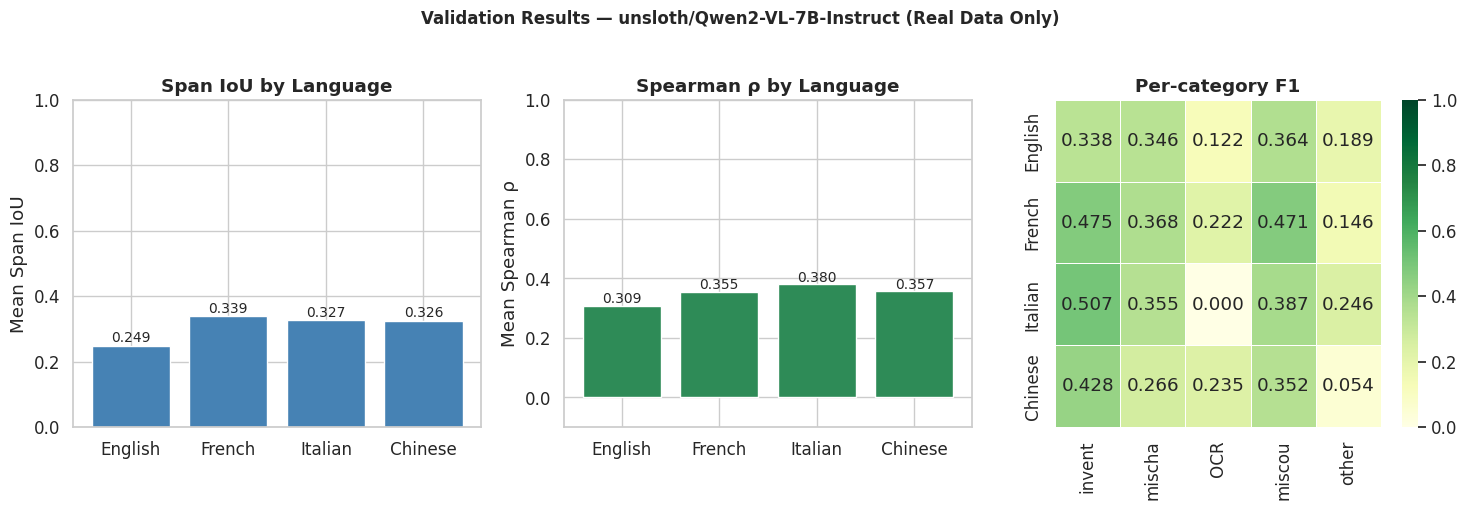

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

langs_eval = [l for l in LANGUAGES if l in results_by_lang]
lang_labels = [LANG_NAMES[l] for l in langs_eval]

# IoU per language
ax = axes[0]
ious = [results_by_lang[l]['mean_iou'] for l in langs_eval]
bars = ax.bar(lang_labels, ious, color='steelblue', edgecolor='white')
ax.set_title('Span IoU by Language', fontweight='bold')
ax.set_ylabel('Mean Span IoU')
ax.set_ylim(0, 1)
for bar, v in zip(bars, ious):
    ax.text(bar.get_x()+bar.get_width()/2, v+0.01, f'{v:.3f}', ha='center', fontsize=10)

# Spearman per language
ax2 = axes[1]
rhos = [results_by_lang[l]['mean_spearman'] for l in langs_eval]
bars2 = ax2.bar(lang_labels, rhos, color='seagreen', edgecolor='white')
ax2.set_title('Spearman ρ by Language', fontweight='bold')
ax2.set_ylabel('Mean Spearman ρ')
ax2.set_ylim(-0.1, 1)
for bar, v in zip(bars2, rhos):
    ax2.text(bar.get_x()+bar.get_width()/2, max(v+0.01, 0.02), f'{v:.3f}', ha='center', fontsize=10)

# Category F1 heatmap
ax3 = axes[2]
f1_matrix = [[results_by_lang[l]['cat_f1'].get(c, 0.0) for c in LABEL_ORDER]
             for l in langs_eval]
sns.heatmap(f1_matrix,
            xticklabels=[f'{c[:6]}' for c in LABEL_ORDER],
            yticklabels=lang_labels,
            annot=True, fmt='.3f', cmap='YlGn',
            vmin=0, vmax=1, ax=ax3, linewidths=0.5)
ax3.set_title('Per-category F1', fontweight='bold')

plt.suptitle(f'Validation Results — {MODEL_ID} (Real Data Only)',
             fontsize=12, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'baseline_results.png', dpi=150, bbox_inches='tight')
plt.show()

---
## 7 — Error Analysis

Understanding where the model fails guides the synthetic augmentation design.


In [ ]:
# ── Categorise prediction errors ──────────────────────────────────────────────
def classify_outcome(pred: list, gold: list) -> str:
    has_pred = bool(pred)
    has_gold = bool(gold)
    iou = span_iou(pred, gold)
    if not has_pred and not has_gold:
        return 'TN (correct clean)'        # correctly predicted no hallucination
    if has_pred and not has_gold:
        return 'FP (false alarm)'          # predicted hallucination on clean sample
    if not has_pred and has_gold:
        return 'FN (missed hallu)'         # missed a hallucination
    if iou >= 0.5:
        return 'TP (correct hallucination)'# correct detection
    return 'Partial (wrong span/category)' # detected something but imprecise

outcomes = Counter()
for conv in all_val_limited:
    pred = val_predictions.get(conv['_id'], [])
    gold = conv['_labels']
    outcomes[classify_outcome(pred, gold)] += 1

print('Prediction Outcome Analysis (validation set):')
total = sum(outcomes.values())
for outcome, count in sorted(outcomes.items(), key=lambda x: -x[1]):
    print(f'  {outcome:35s}: {count:5d} ({count/total*100:.1f}%)')

print()
# ── Category confusion ────────────────────────────────────────────────────────
confusions = Counter()  # (true_label, pred_label)
for conv in all_val_limited:
    pred_spans = val_predictions.get(conv['_id'], [])
    gold_spans = conv['_labels']
    for g in gold_spans:
        gc = set(range(g['start'], g['end']))
        best_p = None
        best_iou = 0.0
        for p in pred_spans:
            pc = set(range(p['start'], p['end']))
            iou = len(gc & pc) / max(len(gc | pc), 1)
            if iou > best_iou:
                best_iou, best_p = iou, p
        if best_p and best_iou >= 0.3:
            confusions[(g['label'], best_p['label'])] += 1

print('Top category confusions (true → predicted):')
for (true_l, pred_l), count in confusions.most_common(10):
    tag = '✓' if true_l == pred_l else '✗'
    print(f'  {tag} {true_l:22s} → {pred_l:22s}: {count}')

Prediction Outcome Analysis (validation set):
  Partial (wrong span/category)      :   490 (61.3%)
  TP (correct hallucination)         :   202 (25.2%)
  FN (missed hallu)                  :   108 (13.5%)

Top category confusions (true → predicted):
  ✓ invention              → invention             : 332
  ✓ mischaracterization    → mischaracterization   : 235
  ✗ mischaracterization    → invention             : 129
  ✓ miscounting            → miscounting           : 103
  ✗ invention              → mischaracterization   : 64
  ✗ OCR                    → invention             : 26
  ✓ OCR                    → OCR                   : 24
  ✓ other                  → other                 : 14
  ✗ other                  → invention             : 13
  ✗ other                  → mischaracterization   : 9


In [ ]:
# ── Show worst predictions (lowest IoU, non-trivial gold labels) ───────────────
scored = []
for conv in all_val_limited:
    if not conv['_labels']:  # skip clean samples
        continue
    pred = val_predictions.get(conv['_id'], [])
    scored.append((conv, pred, span_iou(pred, conv['_labels'])))

scored.sort(key=lambda x: x[2])

print('=== 3 WORST PREDICTIONS (lowest IoU on hallucinated samples) ===')
for conv, pred, iou in scored[:3]:
    print(f'\nID   : {conv["_id"]}  [lang={conv["_lang"]}]  IoU={iou:.3f}')
    print(f'Resp : {conv["_response"][:150]!r}')
    print(f'Gold : {[(lb["label"], lb["start"], lb["end"]) for lb in conv["_labels"][:3]]}')
    print(f'Pred : {[(p["label"], p["start"], p["end"]) for p in pred[:3]]}')

print('\n=== 3 BEST PREDICTIONS (highest IoU on hallucinated samples) ===')
for conv, pred, iou in scored[-3:]:
    print(f'\nID   : {conv["_id"]}  [lang={conv["_lang"]}]  IoU={iou:.3f}')
    print(f'Resp : {conv["_response"][:150]!r}')
    print(f'Gold : {[(lb["label"], lb["start"], lb["end"]) for lb in conv["_labels"][:3]]}')
    print(f'Pred : {[(p["label"], p["start"], p["end"]) for p in pred[:3]]}')

=== 3 WORST PREDICTIONS (lowest IoU on hallucinated samples) ===

ID   : train-en-9668  [lang=en]  IoU=0.000
Resp : 'The map was produced in 1837.'
Gold : [('OCR', 24, 26), ('OCR', 26, 27), ('OCR', 27, 28)]
Pred : []

ID   : train-en-1383  [lang=en]  IoU=0.000
Resp : 'The image shows an aircraft that has been modified to be used as an air ambulance. It is not a traditional ambulance with four wheels. This type of ai'
Gold : [('mischaracterization', 42, 50)]
Pred : [('invention', 196, 214), ('invention', 265, 361)]

ID   : train-en-10164  [lang=en]  IoU=0.000
Resp : 'Yes, this is a bathtub — specifically, it appears to be a **Japanese-style wooden bathtub**, often called a **“ofuro”** (お風呂). It is designed and used'
Gold : [('invention', 25, 124), ('invention', 1054, 1074), ('invention', 1165, 1185)]
Pred : []

=== 3 BEST PREDICTIONS (highest IoU on hallucinated samples) ===

ID   : train-zh-16846  [lang=zh]  IoU=1.000
Resp : '在这张图片中，有几根铁杆。'
Gold : [('miscounting', 8, 9)]
Pred : [('misc

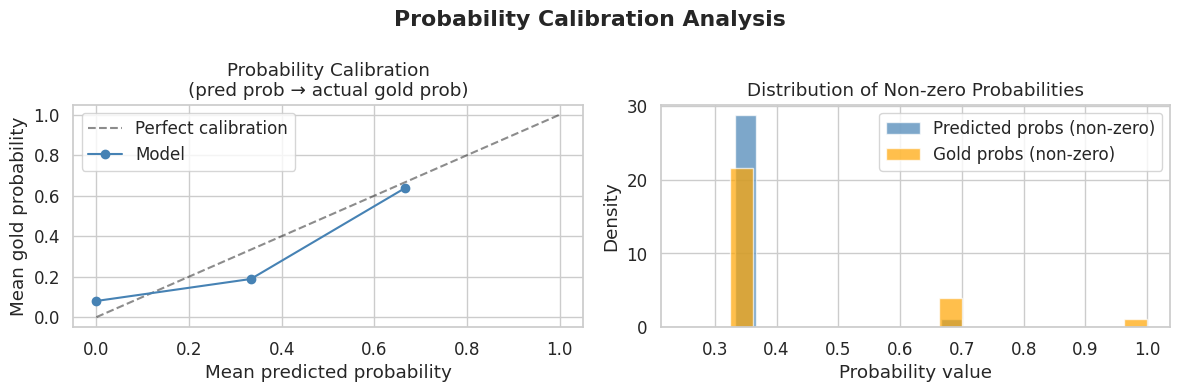

In [ ]:
# ── Probability calibration: predicted prob vs gold prob ──────────────────────
pred_probs, gold_probs = [], []

for conv in all_val_limited:
    resp_len = len(conv['_response'])
    pred_arr = np.zeros(resp_len)
    for s in val_predictions.get(conv['_id'], []):
        for i in range(s['start'], min(s['end'], resp_len)):
            pred_arr[i] = max(pred_arr[i], s['prob'])
    gold_arr = np.zeros(resp_len)
    for s in conv['_labels']:
        for i in range(s['start'], min(s['end'], resp_len)):
            gold_arr[i] = max(gold_arr[i], s['prob'])
    pred_probs.extend(pred_arr.tolist())
    gold_probs.extend(gold_arr.tolist())

pred_probs = np.array(pred_probs)
gold_probs = np.array(gold_probs)

# Reliability diagram (calibration plot)
bins = np.linspace(0, 1, 11)
bin_means_pred, bin_means_gold = [], []
for lo, hi in zip(bins[:-1], bins[1:]):
    mask = (pred_probs >= lo) & (pred_probs < hi)
    if mask.sum() > 0:
        bin_means_pred.append(pred_probs[mask].mean())
        bin_means_gold.append(gold_probs[mask].mean())

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
ax = axes[0]
ax.plot([0,1], [0,1], 'k--', alpha=0.5, label='Perfect calibration')
ax.plot(bin_means_pred, bin_means_gold, 'o-', color='steelblue', label='Model')
ax.set_title('Probability Calibration\n(pred prob → actual gold prob)')
ax.set_xlabel('Mean predicted probability')
ax.set_ylabel('Mean gold probability')
ax.legend()

ax2 = axes[1]
ax2.hist(pred_probs[pred_probs > 0], bins=20, color='steelblue', alpha=0.7,
         density=True, label='Predicted probs (non-zero)')
ax2.hist(gold_probs[gold_probs > 0], bins=20, color='orange', alpha=0.7,
         density=True, label='Gold probs (non-zero)')
ax2.set_title('Distribution of Non-zero Probabilities')
ax2.set_xlabel('Probability value')
ax2.set_ylabel('Density')
ax2.legend()

plt.suptitle('Probability Calibration Analysis', fontweight='bold')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'calibration.png', dpi=150, bbox_inches='tight')
plt.show()

---
## 8 — Official Test Set Prediction

Generate predictions for all 4 language test sets.  
These are saved as JSONL files in the same format as the training labels.


In [ ]:
CKPT_TEST = CKPT_DIR / 'test_preds.json'  # checkpoint for resuming

def load_ckpt(path):
    return json.loads(path.read_text(encoding='utf-8')) if path.exists() else {}

def save_ckpt(path, data):
    path.write_text(json.dumps(data, ensure_ascii=False, indent=2), encoding='utf-8')


all_test_preds = load_ckpt(CKPT_TEST)
n_existing = len(all_test_preds)
if n_existing:
    print(f'Resuming from checkpoint: {n_existing} predictions already saved.')

for lang in LANGUAGES:
    samples = test_raw[lang]
    print(f'\nProcessing test-{lang.upper()} ({len(samples)} samples)...')

    todo = [s for s in samples if s['id'] not in all_test_preds]
    if not todo:
        print('  Already complete (checkpoint).')
        continue

    for i, sample in enumerate(tqdm(todo, desc=lang.upper())):
        conv = build_inference_conversation(sample, IMAGE_DIR)
        if conv is None:
            all_test_preds[sample['id']] = []
            continue
        try:
            all_test_preds[sample['id']] = predict_one(conv)
        except Exception as e:
            print(f'  Error on {sample["id"]}: {e}')
            all_test_preds[sample['id']] = []

        if (i + 1) % 50 == 0:
            save_ckpt(CKPT_TEST, all_test_preds)

    save_ckpt(CKPT_TEST, all_test_preds)

print(f'\nTest predictions complete: {len(all_test_preds):,} samples.')


Processing test-EN (1201 samples)...


EN:   0%|          | 0/1201 [00:00<?, ?it/s]

Both `max_new_tokens` (=512) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=512) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=512) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=512) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_gene

KeyboardInterrupt: 

In [ ]:
# ── Write output JSONL files ──────────────────────────────────────────────────
for lang in LANGUAGES:
    samples  = test_raw[lang]
    out_path = OUTPUT_DIR / f'ft_predictions.test.{lang}.jsonl'

    with open(out_path, 'w', encoding='utf-8') as f:
        for sample in samples:
            resp_len = len(sample['response'])
            raw_preds = all_test_preds.get(sample['id'], [])

            valid_spans = []
            for p in raw_preds:
                s = max(0, min(p['start'], resp_len))
                e = max(s,  min(p['end'],   resp_len))
                if s < e:
                    valid_spans.append({'start': s, 'end': e,
                                        'prob': round(p['prob'], 6),
                                        'label': p['label']})

            record = {'id': sample['id'], 'split': 'test',
                      'language': sample.get('language', lang),
                      'labels': valid_spans}
            f.write(json.dumps(record, ensure_ascii=False) + '\n')

    print(f'Saved {len(samples)} records → {out_path}')

print('\nAll output files saved!')

In [ ]:
# ── Prediction summary statistics ─────────────────────────────────────────────
print('=== TEST SET PREDICTION SUMMARY ===')
for lang in LANGUAGES:
    samples = test_raw[lang]
    preds   = {s['id']: all_test_preds.get(s['id'], []) for s in samples}
    n_hallu = sum(1 for p in preds.values() if p)
    n_spans = sum(len(p) for p in preds.values())
    ldist   = Counter(sp['label'] for spans in preds.values() for sp in spans)
    print(f'\n[{lang.upper()}]')
    print(f'  Samples with hallucination : {n_hallu}/{len(samples)} ({100*n_hallu//len(samples)}%)')
    print(f'  Total spans predicted      : {n_spans}')
    print(f'  Label dist: {dict(ldist)}')

print()
print('--- Training label distribution (reference) ---')
for lang in LANGUAGES:
    spans = [lb for s in train_raw[lang] for lb in s.get('labels', [])]
    cnt   = Counter(lb['label'] for lb in spans)
    total = len(spans)
    print(f'[{lang.upper()}] {dict(cnt)}')

---
## 9 — Baseline Comparison Template

This cell produces the **thesis comparison table** to fill in after running  
the synthetic augmentation notebook (Stage 2).


THESIS COMPARISON TABLE (fill in TBD after running Stage 2):
                                         Configuration Span IoU Spearman ρ Cat F1 (macro)
                                       Random baseline        —          —              —
Qwen2-VL-7B-Instruct (real data only)  ← THIS NOTEBOOK   0.3102     0.3500         0.2861
          Qwen2-VL-7B-Instruct + S4 Agreement upsample      TBD        TBD            TBD
     Qwen2-VL-7B-Instruct + S1 Hallucination injection      TBD        TBD            TBD
      Qwen2-VL-7B-Instruct + S2 Cross-lingual transfer      TBD        TBD            TBD
   Qwen2-VL-7B-Instruct + All strategies (S1+S2+S3+S4)      TBD        TBD            TBD

Saved template → /content/drive/MyDrive/shroom-visions/ft_predictions/thesis_comparison_table.csv


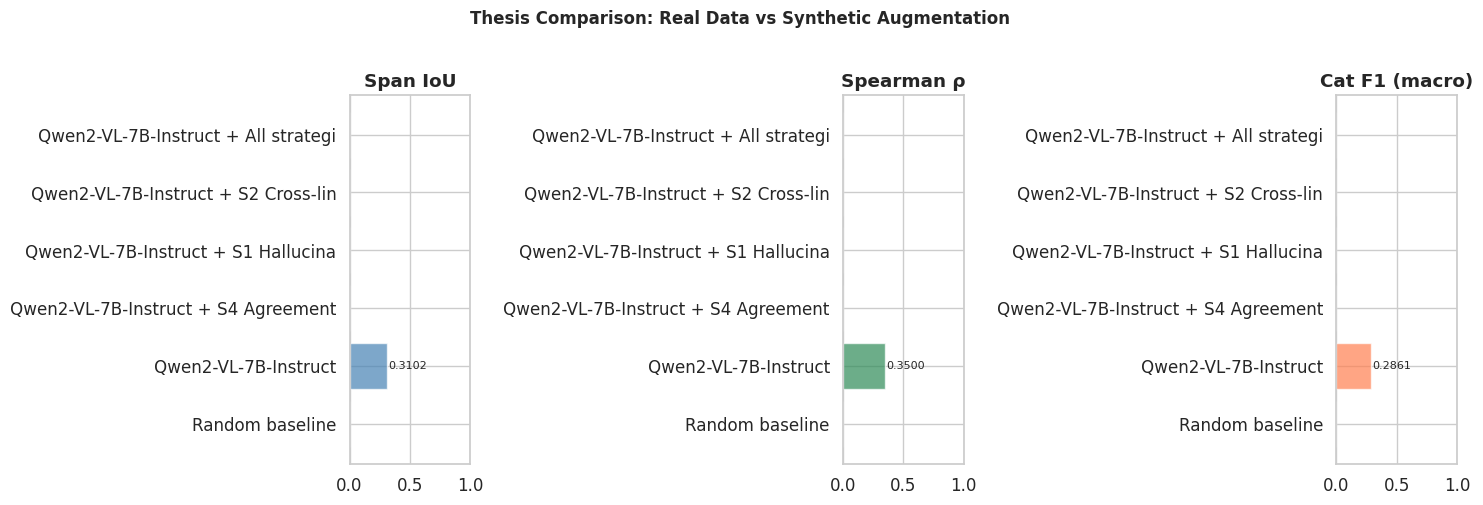

Comparison chart saved (update values in Stage 2 notebook).


In [ ]:
# ── Thesis comparison table template ─────────────────────────────────────────
# Fill in the synthetic augmentation results after Stage 2

comparison = pd.DataFrame({
    'Configuration': [
        'Random baseline',
        f'{MODEL_ID.split("/")[-1]} (real data only)  ← THIS NOTEBOOK',
        f'{MODEL_ID.split("/")[-1]} + S4 Agreement upsample',
        f'{MODEL_ID.split("/")[-1]} + S1 Hallucination injection',
        f'{MODEL_ID.split("/")[-1]} + S2 Cross-lingual transfer',
        f'{MODEL_ID.split("/")[-1]} + All strategies (S1+S2+S3+S4)',
    ],
    'Span IoU': [
        '—',
        f'{overall["mean_iou"]:.4f}',
        'TBD', 'TBD', 'TBD', 'TBD',
    ],
    'Spearman ρ': [
        '—',
        f'{overall["mean_spearman"]:.4f}',
        'TBD', 'TBD', 'TBD', 'TBD',
    ],
    'Cat F1 (macro)': [
        '—',
        f'{overall["cat_f1"]["macro"]:.4f}',
        'TBD', 'TBD', 'TBD', 'TBD',
    ],
})

print('THESIS COMPARISON TABLE (fill in TBD after running Stage 2):')
print(comparison.to_string(index=False))

comparison.to_csv(OUTPUT_DIR / 'thesis_comparison_table.csv', index=False)
print(f'\nSaved template → {OUTPUT_DIR / "thesis_comparison_table.csv"}')

# Plot comparison (will show gaps for TBD entries)
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
metrics_to_plot = [('Span IoU', 'steelblue'), ('Spearman ρ', 'seagreen'), ('Cat F1 (macro)', 'coral')]

configs = comparison['Configuration'].tolist()
short_labels = [c.split('(')[0].strip()[:35] for c in configs]

for ax, (metric, color) in zip(axes, metrics_to_plot):
    vals = []
    for v in comparison[metric]:
        try:
            vals.append(float(v))
        except (ValueError, TypeError):
            vals.append(0.0)
    bars = ax.barh(short_labels, vals, color=color, alpha=0.7, edgecolor='white')
    ax.set_title(metric, fontweight='bold')
    ax.set_xlim(0, 1)
    for bar, v in zip(bars, vals):
        if v > 0:
            ax.text(v + 0.01, bar.get_y()+bar.get_height()/2, f'{v:.4f}', va='center', fontsize=8)

plt.suptitle('Thesis Comparison: Real Data vs Synthetic Augmentation',
             fontsize=12, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'thesis_comparison.png', dpi=150, bbox_inches='tight')
plt.show()
print('Comparison chart saved (update values in Stage 2 notebook).')

---
## Summary

### What this notebook produced

| Artifact | Location |
|---|---|
| Trained LoRA adapter | `ft_checkpoints/final_adapter/` |
| Validation results (CSV) | `ft_predictions/baseline_results.csv` |
| Test predictions (JSONL, 4 langs) | `ft_predictions/ft_predictions.test.{lang}.jsonl` |
| Thesis comparison table template | `ft_predictions/thesis_comparison_table.csv` |
| Training loss curve | `ft_predictions/training_loss.png` |
| Probability calibration plot | `ft_predictions/calibration.png` |

### Next step: Stage 2 — Synthetic Augmentation
Apply augmentation strategies from the analysis notebook (S1–S4) and re-run training  
with `train_raw[lang] + synthetic_samples[lang]`. Compare the two results using  
`baseline_results.csv` as the reference.

### Key things to monitor when adding synthetic data
1. **OCR F1** — most likely to improve (was severely underrepresented)
2. **ZH IoU** — ZH had fewest hallucinations in training; synthetic injection should help most
3. **Calibration** — synthetic samples should have `prob=1.0` (high certainty) to reduce label noise
4. **Overall Span IoU** — the primary metric for the shared task leaderboard
